# Practical Work 4 — Linear Regression

## Feature Selection and Multicollinearity Analysis

**Variant:** B

**Dataset:** Auto MPG

**Target variable:** mpg

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data_path = Path("../data/mpg.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [4]:
df["horsepower"] = pd.to_numeric(
    df["horsepower"],
    errors="coerce"
)

print("Missing values:")
print(df.isnull().sum())

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


## Feature Selection

The target variable is mpg.

The numerical features are:
- cylinders
- displacement
- horsepower
- weight
- acceleration
- model_year

The columns name and origin are excluded from the numerical feature set.

The name column is textual and identifies the car model. The origin column is a numerical code representing a category, not a continuous measurement.

In [5]:
numerical_features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

X = df[numerical_features].copy()
y = df["mpg"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (398, 6)
Target shape: (398,)


## Train-Test Split

The dataset is divided into training and testing sets before preprocessing.

The training set is used to fit the preprocessing pipeline and train the model. The testing set is used only for final evaluation.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (318, 6)
X_test: (80, 6)
y_train: (318,)
y_test: (80,)


## Multicollinearity Analysis

Multicollinearity occurs when two or more independent features are strongly correlated.

The correlation matrix is calculated using only the training data to avoid data leakage.

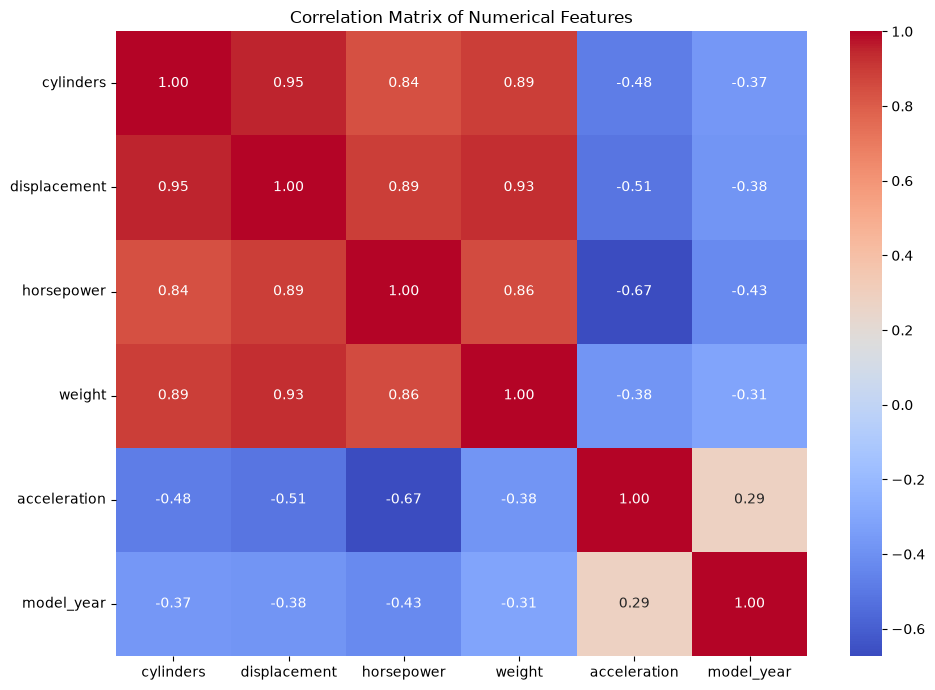

In [7]:
correlation_matrix = X_train.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [8]:
high_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[i, j]

        if abs(value) >= 0.85:
            high_correlations.append((
                correlation_matrix.columns[i],
                correlation_matrix.columns[j],
                round(value, 3)
            ))

print("Highly correlated feature pairs:")

for pair in high_correlations:
    print(pair)

Highly correlated feature pairs:
('cylinders', 'displacement', np.float64(0.952))
('cylinders', 'weight', np.float64(0.894))
('displacement', 'horsepower', np.float64(0.889))
('displacement', 'weight', np.float64(0.929))
('horsepower', 'weight', np.float64(0.855))


## Reduced Feature Set

The reduced model uses four features:

- horsepower
- weight
- acceleration
- model_year

The features cylinders and displacement are excluded to reduce redundancy between engine-related variables.

The baseline and reduced models will be compared using the same train-test split.

In [9]:
reduced_features = [
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

X_train_reduced = X_train[reduced_features]
X_test_reduced = X_test[reduced_features]

print("Baseline features:", X_train.shape[1])
print("Reduced features:", X_train_reduced.shape[1])

Baseline features: 6
Reduced features: 4


## Baseline Linear Regression Model

The baseline model uses all six numerical features.

The preprocessing pipeline fills missing values using the median and scales the features using StandardScaler.

The pipeline is fitted only on the training data.

In [10]:
baseline_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

baseline_pipeline.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [11]:
reduced_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

reduced_pipeline.fit(X_train_reduced, y_train)

print("Reduced model trained successfully!")

Reduced model trained successfully!


In [12]:
baseline_predictions = baseline_pipeline.predict(X_test)

reduced_predictions = reduced_pipeline.predict(X_test_reduced)

print("Predictions generated successfully!")
print("Number of test predictions:", len(baseline_predictions))

Predictions generated successfully!
Number of test predictions: 80


## Model Evaluation

Both models are evaluated on the same test set.

MAE and RMSE are measured in miles per gallon (MPG). R² is a dimensionless metric.

In [13]:
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


baseline_results = evaluate_model(
    y_test,
    baseline_predictions,
    "Baseline Model"
)

reduced_results = evaluate_model(
    y_test,
    reduced_predictions,
    "Reduced Model"
)

results = pd.DataFrame([
    baseline_results,
    reduced_results
])

display(results.round(3))

,Model,MAE,RMSE,R2
0,Baseline Model,2.467,3.072,0.824
1,Reduced Model,2.456,3.065,0.825


## Actual vs Predicted Values

This plot compares the actual MPG values with the values predicted by the baseline and reduced models.

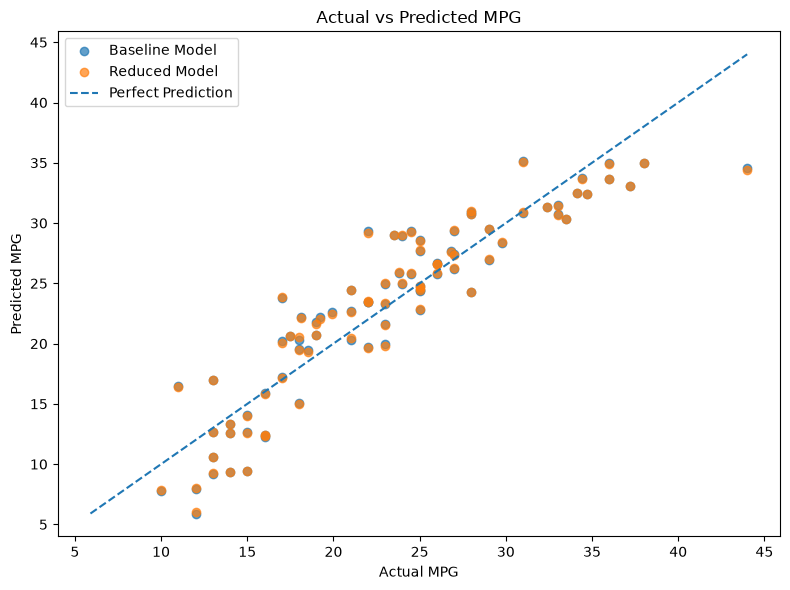

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    baseline_predictions,
    alpha=0.7,
    label="Baseline Model"
)

plt.scatter(
    y_test,
    reduced_predictions,
    alpha=0.7,
    label="Reduced Model"
)

min_value = min(y_test.min(), baseline_predictions.min(), reduced_predictions.min())
max_value = max(y_test.max(), baseline_predictions.max(), reduced_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")
plt.legend()
plt.tight_layout()
plt.show()

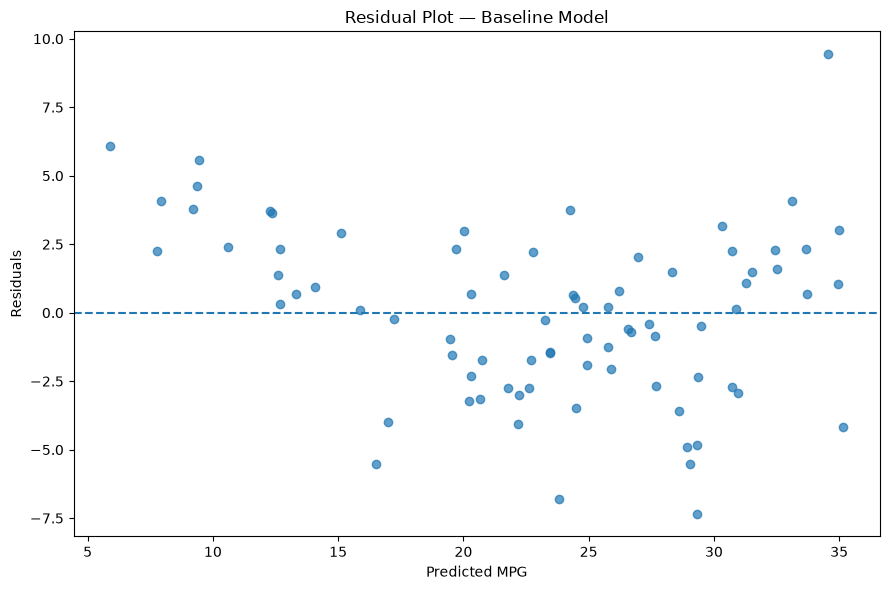

In [15]:
baseline_residuals = y_test - baseline_predictions
reduced_residuals = y_test - reduced_predictions

plt.figure(figsize=(9, 6))

plt.scatter(
    baseline_predictions,
    baseline_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted MPG")
plt.ylabel("Residuals")
plt.title("Residual Plot — Baseline Model")
plt.tight_layout()
plt.show()

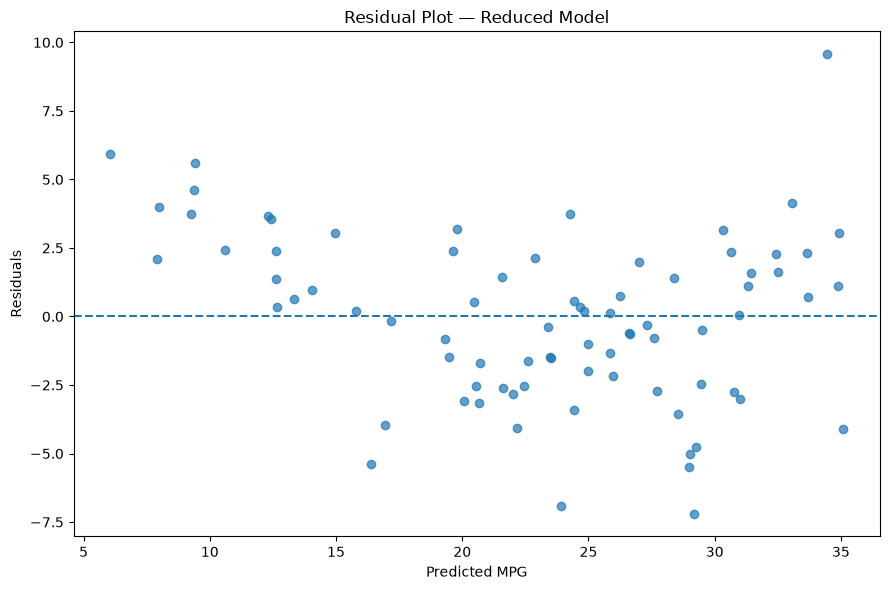

In [16]:
plt.figure(figsize=(9, 6))

plt.scatter(
    reduced_predictions,
    reduced_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted MPG")
plt.ylabel("Residuals")
plt.title("Residual Plot — Reduced Model")
plt.tight_layout()
plt.show()

In [17]:
best_model_name = results.loc[
    results["RMSE"].idxmin(),
    "Model"
]

print("Model with the lowest test RMSE:", best_model_name)

Model with the lowest test RMSE: Reduced Model


## Conclusion

In this practical work, two Linear Regression models were trained and compared.

The baseline model used six numerical features, while the reduced model used four features.

Multicollinearity was examined using a correlation matrix calculated on the training data.

The preprocessing pipeline included median imputation and feature scaling. It was fitted only on the training data to prevent data leakage.

The models were evaluated using MAE, RMSE and R² on the test set.

The baseline model achieved:
- MAE: [value] MPG
- RMSE: [value] MPG
- R²: [value]

The reduced model achieved:
- MAE: [value] MPG
- RMSE: [value] MPG
- R²: [value]

The model with the lower test RMSE was [model name].

The final feature set was selected by considering prediction errors, R², multicollinearity and residual plots.

The results show that removing redundant features [improved / did not improve] the model performance.